/Users/dzmitryshautsou/PycharmProjects/PythonProject3/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Missing values before cleaning:
 Ticker
MDLZ    0
PEP     0
SPY     0
dtype: int64 

Full sample: 2009-01-02 to 2026-11-18  (4498 days)
Formation:   2009-01-02 to 2019-12-31  (2768 days)
Trading:     2020-01-02 to 2026-11-18  (1730 days)
Ticker             PEP       MDLZ         SPY
Date                                         
2026-11-12  142.259995  66.559998  757.119995
2026-11-13  145.440002  67.540001  754.369995
2026-11-16  146.429993  67.540001  739.950012
2026-11-17  142.020004  66.750000  732.440002
2026-11-18  142.054993  66.669998  730.760010


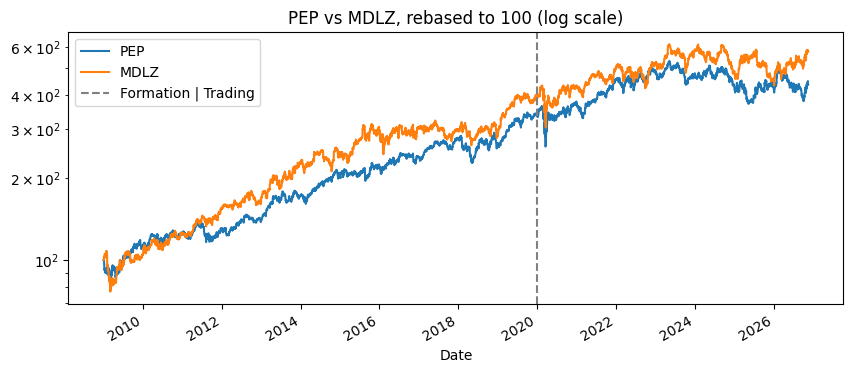

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint

A, B = "PEP", "MDLZ"
MKT = "SPY"
START = "2009-01-01"
FORMATION_END = "2019-12-31"
ENTRY_Z, EXIT_Z = 2.0, 0.0
COST_BP = 5

raw = yf.download([A, B, MKT], start=START, auto_adjust=True, progress=False)["Close"]
print("Missing values before cleaning:\n", raw.isna().sum(), "\n")
px = raw[[A, B, MKT]].dropna()

lp = np.log(px)
rets = lp.diff().dropna()

form = lp.loc[:FORMATION_END]
trade = lp.loc[lp.index > FORMATION_END]

print(f"Full sample: {px.index[0].date()} to {px.index[-1].date()}  ({len(px)} days)")
print(f"Formation:   {form.index[0].date()} to {form.index[-1].date()}  ({len(form)} days)")
print(f"Trading:     {trade.index[0].date()} to {trade.index[-1].date()}  ({len(trade)} days)")
print(px.tail())

ax = (px[[A, B]] / px[[A, B]].iloc[0] * 100).plot(
    logy=True, figsize=(10, 4), title=f"{A} vs {B}, rebased to 100 (log scale)")
ax.axvline(pd.Timestamp(FORMATION_END), color="grey", ls="--", label="Formation | Trading")
ax.legend()
plt.show()

alpha = 1.154, beta = 0.926, R2 = 0.971
EG stat = -3.67, 5% crit = -3.34, p = 0.0199, reverse p = 0.0192
Spread mean = -0.0000, std = 0.0870
Stationary -> trade


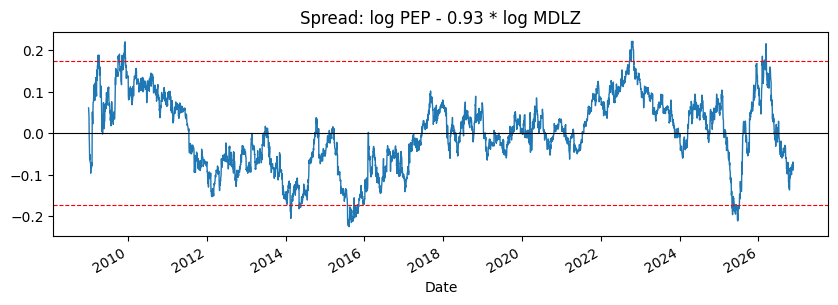

In [3]:
y, x = lp[A], lp[B]
ols = sm.OLS(y, sm.add_constant(x)).fit()
alpha, beta = ols.params
spread = y - alpha - beta * x
mu, sigma = spread.mean(), spread.std()

stat, p, crit = coint(y, x)
p_rev = coint(x, y)[1]

print(f"alpha = {alpha:.3f}, beta = {beta:.3f}, R2 = {ols.rsquared:.3f}")
print(f"EG stat = {stat:.2f}, 5% crit = {crit[1]:.2f}, p = {p:.4f}, reverse p = {p_rev:.4f}")
print(f"Spread mean = {mu:.4f}, std = {sigma:.4f}")
print("Stationary -> trade" if p < 0.05 else "Not stationary -> don't trade")

ax = spread.plot(figsize=(10, 3), lw=1, title=f"Spread: log {A} - {beta:.2f} * log {B}")
ax.axhline(mu, color="black", lw=0.8)
ax.axhline(mu + 2 * sigma, color="red", ls="--", lw=0.8)
ax.axhline(mu - 2 * sigma, color="red", ls="--", lw=0.8)
plt.show()

alpha = 1.154, beta = 0.926, R2 = 0.971
EG stat = -3.67, 5% crit = -3.34, p = 0.0199, reverse p = 0.0192
Spread mean = -0.0000, std = 0.0870
Stationary -> trade


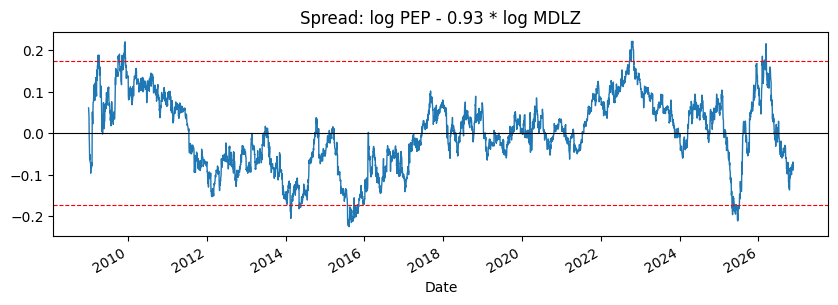

In [4]:
y, x = lp[A], lp[B]
ols = sm.OLS(y, sm.add_constant(x)).fit()
alpha, beta = ols.params
spread = y - alpha - beta * x
mu, sigma = spread.mean(), spread.std()

stat, p, crit = coint(y, x)
p_rev = coint(x, y)[1]

print(f"alpha = {alpha:.3f}, beta = {beta:.3f}, R2 = {ols.rsquared:.3f}")
print(f"EG stat = {stat:.2f}, 5% crit = {crit[1]:.2f}, p = {p:.4f}, reverse p = {p_rev:.4f}")
print(f"Spread mean = {mu:.4f}, std = {sigma:.4f}")
print("Stationary -> trade" if p < 0.05 else "Not stationary -> don't trade")

ax = spread.plot(figsize=(10, 3), lw=1, title=f"Spread: log {A} - {beta:.2f} * log {B}")
ax.axhline(mu, color="black", lw=0.8)
ax.axhline(mu + 2 * sigma, color="red", ls="--", lw=0.8)
ax.axhline(mu - 2 * sigma, color="red", ls="--", lw=0.8)
plt.show()

In [5]:
R = px.pct_change()

z = (spread - mu) / sigma
pos = pd.Series(np.nan, index=z.index)
pos[np.sign(z) != np.sign(z.shift(1))] = 0
pos[z > ENTRY_Z] = -1
pos[z < -ENTRY_Z] = 1
pos = pos.ffill().fillna(0)

held = pos.shift(1).fillna(0)
gross = (held * (R[A] - beta * R[B]) / (1 + beta)).fillna(0)
cost = pos.diff().abs().fillna(0) * COST_BP / 1e4
net = gross - cost


def perf(r, held):
    eq = (1 + r).cumprod()
    entries = (held != 0) & (held != held.shift(1))
    trade_pnl = r.groupby(entries.cumsum().where(held != 0)).sum()
    return {
        "total_return": eq.iloc[-1] - 1,
        "ann_return": eq.iloc[-1] ** (252 / len(r)) - 1,
        "ann_vol": r.std() * np.sqrt(252),
        "sharpe": r.mean() / r.std() * np.sqrt(252),
        "max_drawdown": (eq / eq.cummax() - 1).min(),
        "trades": int(entries.sum()),
        "win_rate": (trade_pnl > 0).mean(),
        "avg_hold_days": (held != 0).sum() / max(entries.sum(), 1),
        "time_in_market": (held != 0).mean(),
    }


stats = pd.DataFrame({"gross": perf(gross, held), "net": perf(net, held)})
print(stats.round(4))



                   gross       net
total_return      1.0024    0.9885
ann_return        0.0397    0.0393
ann_vol           0.0438    0.0437
sharpe            0.9109    0.9028
max_drawdown     -0.0530   -0.0530
trades            7.0000    7.0000
win_rate          1.0000    1.0000
avg_hold_days   172.4286  172.4286
time_in_market    0.2683    0.2683


Comparison from 2011-01-04:
                   fixed  wf 126d  wf 252d   wf 504d
total_return      0.7061   1.2967   0.7811    0.0066
ann_return        0.0343   0.0539   0.0371    0.0004
ann_vol           0.0386   0.1448   0.0877    0.0566
sharpe            0.8938   0.4323   0.4589    0.0356
max_drawdown     -0.0480  -0.2419  -0.1501   -0.2268
trades            6.0000  54.0000  29.0000   12.0000
win_rate          1.0000   0.6667   0.8276    0.6667
avg_hold_days   143.6667  42.2593  70.2414  158.1667
time_in_market    0.2159   0.5715   0.5101    0.4753


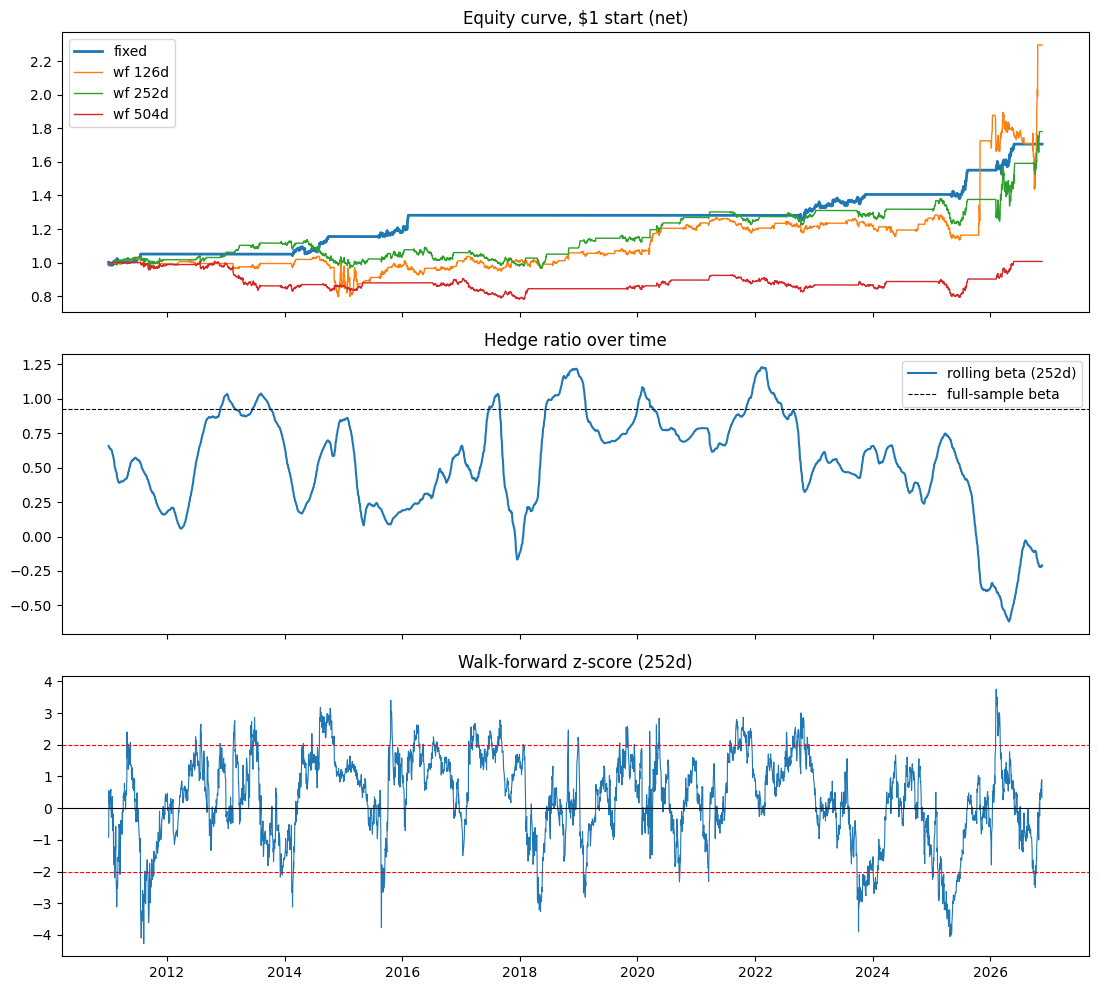

In [6]:
def walk_forward(W):
    la, lb = lp[A], lp[B]
    ma, mb = la.rolling(W).mean().shift(1), lb.rolling(W).mean().shift(1)
    va, vb = la.rolling(W).var().shift(1), lb.rolling(W).var().shift(1)
    cab = la.rolling(W).cov(lb).shift(1)
    b = cab / vb
    mu_t = ma - b * mb
    sd_t = np.sqrt(va - 2 * b * cab + b ** 2 * vb)
    z = (la - b * lb - mu_t) / sd_t

    p = pd.Series(np.nan, index=z.index)
    p[np.sign(z) != np.sign(z.shift(1))] = 0
    p[z > ENTRY_Z] = -1
    p[z < -ENTRY_Z] = 1
    p = p.ffill().fillna(0)

    entry = (p != 0) & (p != p.shift(1))
    hedge = b.where(entry).ffill().where(p != 0).shift(1)
    hp = p.shift(1).fillna(0)
    gross_wf = (hp * (R[A] - hedge * R[B]) / (1 + hedge)).fillna(0)
    net_wf = gross_wf - p.diff().abs().fillna(0) * COST_BP / 1e4
    return net_wf, hp, z, b


WINDOWS = [126, 252, 504]
wf = {w: walk_forward(w) for w in WINDOWS}
start = lp.index[max(WINDOWS) + 1]

cmp = pd.DataFrame({"fixed": perf(net.loc[start:], held.loc[start:])} |
                   {f"wf {w}d": perf(wf[w][0].loc[start:], wf[w][1].loc[start:]) for w in WINDOWS})
print(f"Comparison from {start.date()}:")
print(cmp.round(4))

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
axes[0].plot((1 + net.loc[start:]).cumprod(), label="fixed", lw=2)
for w in WINDOWS:
    axes[0].plot((1 + wf[w][0].loc[start:]).cumprod(), label=f"wf {w}d", lw=1)
axes[0].set_title("Equity curve, $1 start (net)")
axes[0].legend()
axes[1].plot(wf[252][3].loc[start:], label="rolling beta (252d)")
axes[1].axhline(beta, color="black", ls="--", lw=0.8, label="full-sample beta")
axes[1].set_title("Hedge ratio over time")
axes[1].legend()
axes[2].plot(wf[252][2].loc[start:], lw=0.8)
axes[2].axhline(ENTRY_Z, color="red", ls="--", lw=0.8)
axes[2].axhline(-ENTRY_Z, color="red", ls="--", lw=0.8)
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_title("Walk-forward z-score (252d)")
plt.tight_layout()
plt.show()

Share of time without cointegration (3y rolling, p > 0.10): 80.4%

Periods without cointegration (63+ days):
         start         end  days
0  2012-06-04  2012-08-30    63
1  2012-10-02  2014-05-06   399
2  2014-09-05  2020-01-07  1344
3  2022-03-09  2024-06-10   567
4  2024-08-12  2024-11-07    63
5  2025-01-13  2026-11-18   466 

Spread stuck on one side of the mean for 1+ year:
         start         end  days  peak_z
0  2009-05-13  2011-07-20   552    2.54
1  2011-07-21  2013-06-07   473    1.76
2  2013-07-23  2014-09-30   301    2.36
3  2016-02-09  2017-06-15   341    1.67
4  2021-07-21  2023-11-15   586    2.56 

fixed: ann. return when decoupled 3.83%, otherwise 1.32%
wf 252d: ann. return when decoupled 5.02%, otherwise 0.67%


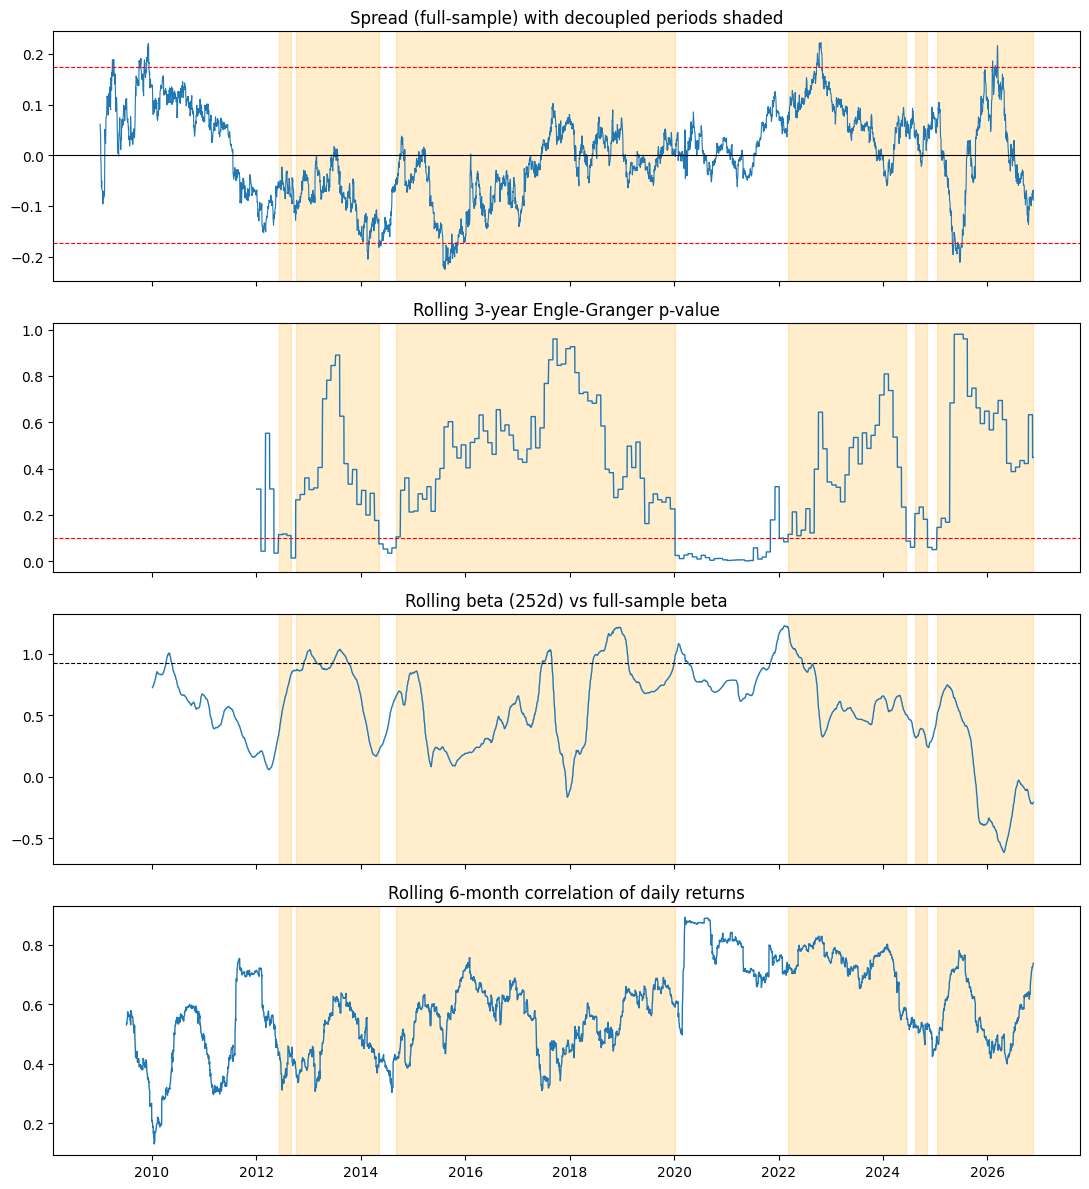

In [7]:
W_EG, STEP = 756, 21
roll_p = pd.Series([coint(lp[A].iloc[i - W_EG:i], lp[B].iloc[i - W_EG:i])[1]
                    for i in range(W_EG, len(lp), STEP)],
                   index=lp.index[W_EG::STEP]).reindex(lp.index).ffill()
flag = roll_p > 0.10

g = (flag != flag.shift()).cumsum()
no_coint = flag[flag].groupby(g[flag]).agg(
    start=lambda s: s.index[0].date(), end=lambda s: s.index[-1].date(), days="size")
no_coint = no_coint[no_coint.days >= 63].reset_index(drop=True)

side = np.sign(spread)
g2 = (side != side.shift()).cumsum()
exc = spread.groupby(g2).agg(
    start=lambda s: s.index[0].date(), end=lambda s: s.index[-1].date(),
    days="size", peak_z=lambda s: (s / sigma).abs().max())
long_exc = exc[exc.days >= 252].reset_index(drop=True)

print(f"Share of time without cointegration (3y rolling, p > 0.10): {flag[roll_p.notna()].mean():.1%}\n")
print("Periods without cointegration (63+ days):\n", no_coint, "\n")
print("Spread stuck on one side of the mean for 1+ year:\n", long_exc.round(2), "\n")

valid = roll_p.notna()
for name, r in [("fixed", net), ("wf 252d", wf[252][0])]:
    print(f"{name}: ann. return when decoupled {r[valid & flag].mean() * 252:.2%}, "
          f"otherwise {r[valid & ~flag].mean() * 252:.2%}")

fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
axes[0].plot(spread, lw=0.8)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].axhline(2 * sigma, color="red", ls="--", lw=0.8)
axes[0].axhline(-2 * sigma, color="red", ls="--", lw=0.8)
axes[0].set_title("Spread (full-sample) with decoupled periods shaded")
axes[1].plot(roll_p, lw=1)
axes[1].axhline(0.10, color="red", ls="--", lw=0.8)
axes[1].set_title("Rolling 3-year Engle-Granger p-value")
axes[2].plot(wf[252][3], lw=1)
axes[2].axhline(beta, color="black", ls="--", lw=0.8)
axes[2].set_title("Rolling beta (252d) vs full-sample beta")
axes[3].plot(R[A].rolling(126).corr(R[B]), lw=1)
axes[3].set_title("Rolling 6-month correlation of daily returns")
for ax in axes:
    for _, row in no_coint.iterrows():
        ax.axvspan(pd.Timestamp(row.start), pd.Timestamp(row.end), color="orange", alpha=0.2)
plt.tight_layout()
plt.show()

In [8]:
print(f"Net dollar exposure per $1 gross: long spread {(1 - beta) / (1 + beta):+.3f}, "
      f"short spread {-(1 - beta) / (1 + beta):+.3f}")

df = pd.concat([net, R[MKT], held], axis=1, keys=["strat", "mkt", "held"]).dropna()


def mkt_beta(d):
    m = sm.OLS(d["strat"], sm.add_constant(d["mkt"])).fit()
    return pd.Series({"alpha_ann": m.params["const"] * 252, "beta": m.params["mkt"],
                      "t_beta": m.tvalues["mkt"], "corr": d["strat"].corr(d["mkt"]),
                      "r2": m.rsquared, "days": len(d)})


expo = pd.DataFrame({
    "all days": mkt_beta(df),
    "in market": mkt_beta(df[df.held != 0]),
    "long spread": mkt_beta(df[df.held == 1]),
    "short spread": mkt_beta(df[df.held == -1]),
}).T
print(expo.round(4))

stock_b = {t: sm.OLS(R[t], sm.add_constant(R[MKT]), missing="drop").fit().params.iloc[1] for t in [A, B]}
pos_b = (stock_b[A] - beta * stock_b[B]) / (1 + beta)
print(f"Stock betas: {A} {stock_b[A]:.2f}, {B} {stock_b[B]:.2f}")
print(f"Position beta per $1 gross: long spread {pos_b:+.3f}, short spread {-pos_b:+.3f}")

Net dollar exposure per $1 gross: long spread +0.038, short spread -0.038
              alpha_ann    beta  t_beta    corr      r2    days
all days         0.0403 -0.0054 -1.4675 -0.0219  0.0005  4497.0
in market        0.1527 -0.0251 -1.6830 -0.0484  0.0023  1207.0
long spread      0.2212 -0.1035 -3.1643 -0.1649  0.0272   360.0
short spread     0.1199  0.0005  0.0320  0.0011  0.0000   847.0
Stock betas: PEP 0.52, MDLZ 0.59
Position beta per $1 gross: long spread -0.014, short spread +0.014
